In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import re, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import ParameterGrid
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

BASE_DIR = "/content/drive/MyDrive/NLP project"

torch.manual_seed(42)
np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [ ]:
train = pd.read_csv(f"{BASE_DIR}/train.csv")
val = pd.read_csv(f"{BASE_DIR}/val.csv")
test = pd.read_csv(f"{BASE_DIR}/test.csv")

classes = sorted(train["status"].unique())
class_to_num = {c: i for i, c in enumerate(classes)}
y_train = torch.tensor(train["status"].map(class_to_num).values)
y_val = val["status"].map(class_to_num).values
y_test = test["status"].map(class_to_num).values

In [ ]:
def tokenize(text):
    return re.findall(r"[a-z0-9']+|[^\sa-z0-9']", text.lower())

train_tokens = [tokenize(t) for t in train["statement"]]

counts = Counter(w for toks in train_tokens for w in toks)
vocab = {"<pad>": 0, "<unk>": 1}
for w, c in counts.items():
    if c >= 2:
        vocab[w] = len(vocab)

lengths = [len(t) for t in train_tokens]
print("p95:", int(np.percentile(lengths, 95)), "| p99:", int(np.percentile(lengths, 99)))
MAX_LEN = min(int(np.percentile(lengths, 99)), 1000)
print("Vocab size:", len(vocab), "| MAX_LEN:", MAX_LEN)

p95: 437 | p99: 832
Vocab size: 24706 | MAX_LEN: 832


In [ ]:
def encode(texts):
    X = np.zeros((len(texts), MAX_LEN), dtype=np.int64)
    for i, text in enumerate(texts):
        ids = [vocab.get(w, 1) for w in tokenize(text)][:MAX_LEN]
        X[i, :len(ids)] = ids
    return torch.tensor(X)

X_train, X_val, X_test = encode(train["statement"]), encode(val["statement"]), encode(test["statement"])
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)

weights = compute_class_weight("balanced", classes=np.arange(len(classes)), y=y_train.numpy())
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float).to(device))

In [ ]:
class TextCNN(nn.Module):
    def __init__(self, vocab_size, n_classes, emb_dim, num_filters, kernels, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.emb_dropout = nn.Dropout(0.2)
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, num_filters, k) for k in kernels])
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(kernels), n_classes)

    def forward(self, x):
        x = self.emb_dropout(self.emb(x)).transpose(1, 2)
        x = torch.cat([F.relu(conv(x)).max(dim=2).values for conv in self.convs], dim=1)
        return self.fc(self.dropout(x))

In [ ]:
EPOCHS = 15
PATIENCE = 3

@torch.no_grad()
def predict(model, X):
    model.eval()
    preds = [model(xb.to(device)).argmax(1).cpu() for (xb,) in DataLoader(TensorDataset(X), batch_size=256)]
    return torch.cat(preds).numpy()

def train_model(emb_dim, dropout, num_filters=200, kernels=(2, 3, 4, 5), lr=5e-4):
    torch.manual_seed(42)
    model = TextCNN(len(vocab), len(classes), emb_dim, num_filters, kernels, dropout).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=1)

    best_f1, best_acc, best_state, wait, history = -1, 0, None, 0, []
    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(xb)

        pred = predict(model, X_val)
        acc = accuracy_score(y_val, pred)
        f1 = f1_score(y_val, pred, average="macro")
        scheduler.step(f1)
        history.append({"epoch": epoch, "train_loss": total_loss / len(X_train),
                        "val_accuracy": acc, "val_macro_f1": f1})
        print(f"  epoch {epoch}: loss={total_loss / len(X_train):.4f} | acc={acc:.4f} | "
              f"macro-F1={f1:.4f} | lr={optimizer.param_groups[0]['lr']:.1e}")

        if f1 > best_f1:
            best_f1, best_acc, wait = f1, acc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break

    train_time = time.time() - start
    model.load_state_dict(best_state)
    return model, best_acc, best_f1, train_time, history

In [ ]:
param_grid = {
    "emb_dim": [300],
    "dropout": [0.3],
    "num_filters": [300],
    "kernels": [(2, 3, 4, 5)],
    "lr": [5e-4],
}

grid = list(ParameterGrid(param_grid))
results = []
best_f1 = -1

for i, params in enumerate(grid, 1):
    print(f"[{i}/{len(grid)}] {params}")
    model, acc, f1, train_time, history = train_model(**params)
    results.append({"params": params, "val_accuracy": acc, "val_macro_f1": f1, "train_time_s": train_time})
    print(f"  -> best epoch: acc={acc:.4f} | macro-F1={f1:.4f} | {train_time:.0f}s\n")

    if f1 > best_f1:
        best_f1, best_model, best_params, best_history, best_train_time = f1, model, params, history, train_time

[1/1] {'dropout': 0.3, 'emb_dim': 300, 'kernels': (2, 3, 4, 5), 'lr': 0.0005, 'num_filters': 300}
  epoch 1: loss=1.2970 | acc=0.6962 | macro-F1=0.6158 | lr=5.0e-04
  epoch 2: loss=0.8346 | acc=0.6846 | macro-F1=0.6335 | lr=5.0e-04
  epoch 3: loss=0.6869 | acc=0.7465 | macro-F1=0.6943 | lr=5.0e-04
  epoch 4: loss=0.6157 | acc=0.6999 | macro-F1=0.6502 | lr=5.0e-04
  epoch 5: loss=0.5352 | acc=0.7645 | macro-F1=0.7035 | lr=5.0e-04
  epoch 6: loss=0.4626 | acc=0.7289 | macro-F1=0.6930 | lr=5.0e-04
  epoch 7: loss=0.4147 | acc=0.7611 | macro-F1=0.7093 | lr=5.0e-04
  epoch 8: loss=0.3671 | acc=0.7401 | macro-F1=0.6938 | lr=5.0e-04
  epoch 9: loss=0.3352 | acc=0.7814 | macro-F1=0.7232 | lr=5.0e-04
  epoch 10: loss=0.3106 | acc=0.7649 | macro-F1=0.7120 | lr=5.0e-04
  epoch 11: loss=0.2944 | acc=0.7287 | macro-F1=0.6919 | lr=2.5e-04
  epoch 12: loss=0.2299 | acc=0.7907 | macro-F1=0.7484 | lr=2.5e-04
  epoch 13: loss=0.1971 | acc=0.7749 | macro-F1=0.7319 | lr=2.5e-04
  epoch 14: loss=0.1853 | a

In [ ]:
results_df = pd.DataFrame(results).sort_values("val_macro_f1", ascending=False)
print("Best:", best_params)
results_df

Best: {'dropout': 0.3, 'emb_dim': 300, 'kernels': (2, 3, 4, 5), 'lr': 0.0005, 'num_filters': 300}


,params,val_accuracy,val_macro_f1,train_time_s
0,"{'dropout': 0.3, 'emb_dim': 300, 'kernels': (2...",0.79067,0.748414,572.038293


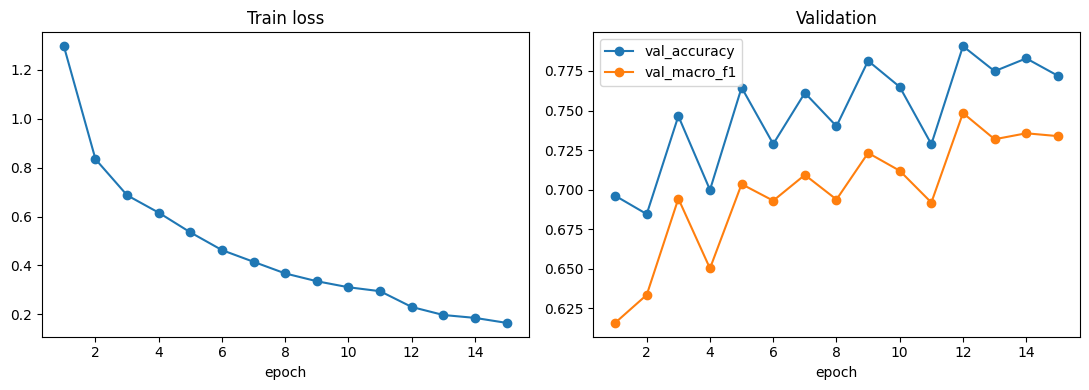

In [ ]:
h = pd.DataFrame(best_history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
h.plot(x="epoch", y="train_loss", ax=axes[0], marker="o", title="Train loss", legend=False)
h.plot(x="epoch", y=["val_accuracy", "val_macro_f1"], ax=axes[1], marker="o", title="Validation")
plt.tight_layout()
plt.show()

Train: 572.0s | Inference: 3.68s
                      precision    recall  f1-score   support

             Anxiety      0.754     0.863     0.805       542
             Bipolar      0.763     0.832     0.796       375
          Depression      0.816     0.621     0.705      2261
              Normal      0.921     0.941     0.931      2403
Personality disorder      0.630     0.560     0.593       134
              Stress      0.681     0.570     0.620       344
            Suicidal      0.642     0.822     0.721      1595

            accuracy                          0.787      7654
           macro avg      0.744     0.744     0.739      7654
        weighted avg      0.796     0.787     0.785      7654



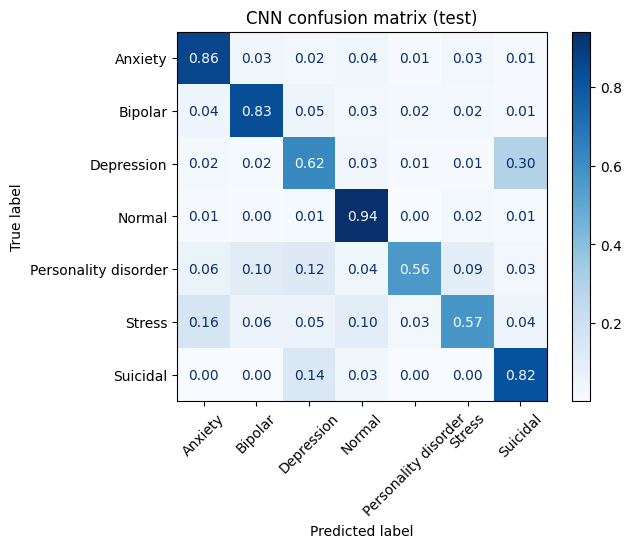

In [ ]:
start = time.time()
X_test_timed = encode(test["statement"])
y_pred_num = predict(best_model, X_test_timed)
inference_time = time.time() - start

y_pred = np.array(classes)[y_pred_num]

print(f"Train: {best_train_time:.1f}s | Inference: {inference_time:.2f}s")
print(classification_report(test["status"], y_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(test["status"], y_pred, normalize="true",
                                        xticks_rotation=45, values_format=".2f", cmap="Blues")
plt.title("CNN confusion matrix (test)")
plt.show()

In [ ]:
pd.DataFrame({"id": test["id"], "true": test["status"], "pred": y_pred}).to_csv(f"{BASE_DIR}/cnn_preds.csv", index=False)

pd.DataFrame([{
    "model": "cnn",
    "accuracy": accuracy_score(test["status"], y_pred),
    "macro_f1": f1_score(test["status"], y_pred, average="macro"),
    "weighted_f1": f1_score(test["status"], y_pred, average="weighted"),
    "train_time_s": best_train_time,
    "inference_time_s": inference_time,
}]).to_csv(f"{BASE_DIR}/cnn_metrics.csv", index=False)

In [ ]:
torch.save({
    "state_dict": best_model.state_dict(),
    "vocab": vocab,
    "classes": classes,
    "max_len": MAX_LEN,
    "params": best_params,
}, f"{BASE_DIR}/cnn_model.pt")

In [ ]:
drive.flush_and_unmount()
from google.colab import runtime
runtime.unassign()